In [125]:
#importing packages I may use in this project.
import numpy as np
import pandas as pd
import datetime
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import statistics
import os


In [126]:
#making sure the spreadsheets and csvs are in the same folder as my current workbook, so I can
#upload them 
print(os.getcwd())

/Users/chessamitchell/Python Block/in_class_notes


### Part 1: Examining the population Pacific Northwest Salmon Species using fish counts.

#### section 1a. Comparison of fish species returning to three locations for 2026

In [127]:
#importing the excel file that has data about the average returns of chinook and other PNW
#salmon species.
chinook_to_other_species_df = pd.read_excel('2026_returns_byspecies.xlsx') 

#### section 1b. Exploratory Data analysis returns in 2026

In [128]:
#This data set shows the number of each species at each data collection site in the 2026 year
#the three locations are Willamette Falls south of Portland oregon in the Willamette River, 
#Bonneville Dam and the Dalles Dams east of Portland on the Columbia River.
#First I want to look at at the data from each locations together.

chinook_to_other_species_df.head(9)

,Species,willamette_falls,bonneville,dalles,year
0,Chinook,38568,540689,231946,2026
1,Jack Chinook,1054,130843,61150,2026
2,Steelhead,17416,61226,38601,2026
3,Wild Steelhead,11166,112730,74575,2026
4,Sockeye,0,40179,25564,2026
5,Coho,0,74033,68222,2026
6,Jack Coho,1921,309403,271512,2026
7,Chum,4959,58348,27529,2026
8,Pink,1732,74687,40213,2026


In [129]:
#As part of my exploratory data, I want to make sure there are no missing values that may impact analysis tasks.
#there are no null values in this data frame.
#Species is a string variable and the other variables are numeric-integers.
#the column year has the same value in it 2026, so as to specify when this collection occured
chinook_to_other_species_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Species           9 non-null      object
 1   willamette_falls  9 non-null      int64 
 2   bonneville        9 non-null      int64 
 3   dalles            9 non-null      int64 
 4   year              9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 492.0+ bytes


In [130]:
#This breaks down some statistics for each fish count in 2026. It may not be helpful because it aggregates the
#different species into one set. It can tell me a few things about the total number of fish counted per site.

chinook_to_other_species_df.describe()

,willamette_falls,bonneville,dalles,year
count,9.000000,9.000000,9.000000,9.0
mean,8535.111111,155793.111111,93256.888889,2026.0
std,12709.478760,165561.850501,92005.141194,0.0
min,0.000000,40179.000000,25564.000000,2026.0
25%,1054.000000,61226.000000,38601.000000,2026.0
50%,1921.000000,74687.000000,61150.000000,2026.0
75%,11166.000000,130843.000000,74575.000000,2026.0
max,38568.000000,540689.000000,271512.000000,2026.0


Section 1b. Report: Bonneville Dam has the highest max value indicating that the most total fish return to the Columbia River. The Dalles Dam has the second highest maximum
number of fish count. The Dalles Dam is upstream of the Bonneville Dam. This will be analyzed further to answer the question, 'Why are there less fish at the Dalles compared to The Bonneville Dam?' Some possible reasons would include predation, fishing, death due to poor environmental conditions, or flaws in the fish count methods at either location.

### 1.c Comparison of species return in 2026 at each location using pie graphs.

#### 1.c.ii Wilamette Falls fish counts for 9 species in 2026

In [131]:
# I am creating a new data frame that shows only the returns for different species at Willamette Falls.
will_falls_2026_df= chinook_to_other_species_df[['Species','willamette_falls']]
will_falls_2026_df

,Species,willamette_falls
0,Chinook,38568
1,Jack Chinook,1054
2,Steelhead,17416
3,Wild Steelhead,11166
4,Sockeye,0
5,Coho,0
6,Jack Coho,1921
7,Chum,4959
8,Pink,1732


In [132]:
#I am going to do some data filtering before creating a visualization
#Here I can see the lowest to highest count for each species. 
#Sockeye and Coho show that 0 fish returned.
sorted_willamette26= will_falls_2026_df.sort_values(by='willamette_falls', ascending= False)
sorted_willamette26

,Species,willamette_falls
0,Chinook,38568
2,Steelhead,17416
3,Wild Steelhead,11166
7,Chum,4959
6,Jack Coho,1921
8,Pink,1732
1,Jack Chinook,1054
4,Sockeye,0
5,Coho,0


In [133]:
#I am creating a new csv with the values only from willamette, with species return sorted from high to low
#I want to keep the zero counts in this data table because I will use it in Tableau.
sorted_willamette26.to_csv('species_to_will_26.csv', index=False)

In [134]:
#In preperation for making a pie chart, 
#I took out the sockeye and coho values because they are zero
#I will make a note that these two species have zero returns in 2026.

non_zero_species = will_falls_2026_df [will_falls_2026_df['willamette_falls'] > 0]
non_zero_species

,Species,willamette_falls
0,Chinook,38568
1,Jack Chinook,1054
2,Steelhead,17416
3,Wild Steelhead,11166
6,Jack Coho,1921
7,Chum,4959
8,Pink,1732


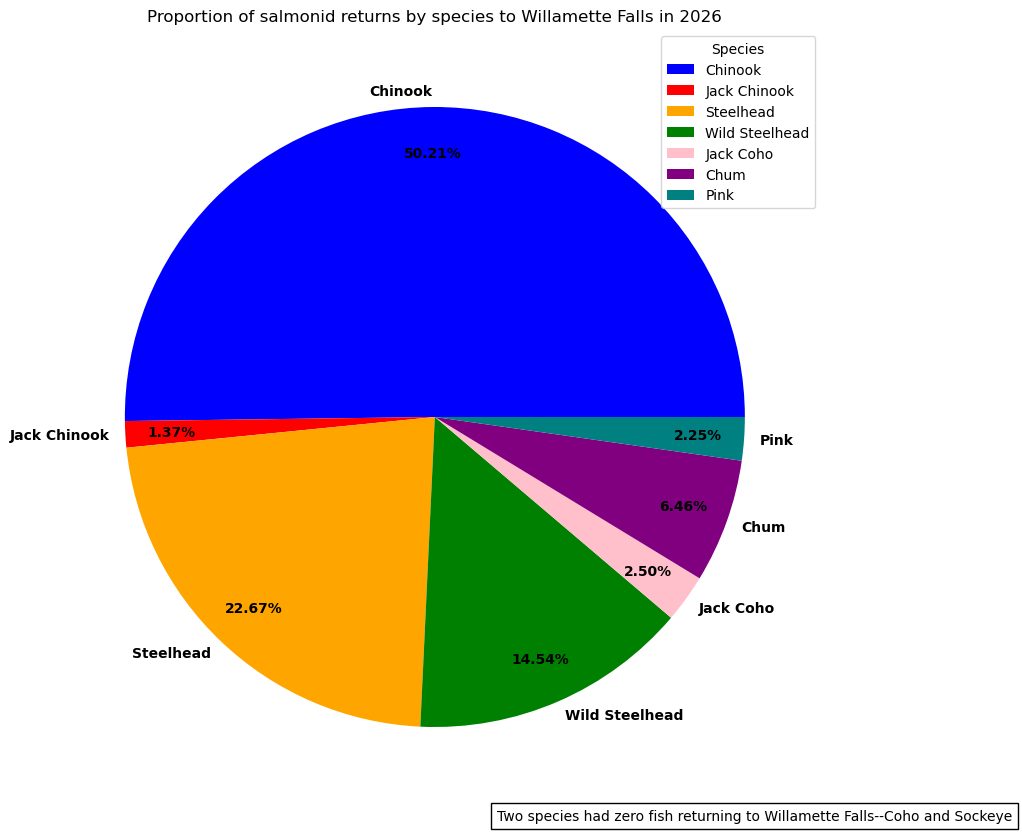

In [135]:
#Here I created a pie chart to show the proportion of total fish counts at each location
plt.figure(figsize= (10, 11))
#this line allows me to change the size of the overall visualization
plt.pie(
    x =non_zero_species['willamette_falls'], 
    labels = non_zero_species['Species'], 
    autopct = '%.2f%%', 
    labeldistance= 1.05, 
    pctdistance = 0.85, 
    textprops={"fontweight": "bold"},
    colors = ('blue', 'red', 'orange', 'green', 'pink', 'purple', 'teal'))
#Lines 4-11 build the plot, specifying the label distance, and the percents for each slice of pie. 
#I added colors, and maded the font bold so you can see them clearly in the colored slices

plt.title('Proportion of salmonid returns by species to Willamette Falls in 2026')
plt.legend(title='Species', loc = 'upper right')
plt.text(0.2, -1.3, 
         'Two species had zero fish returning to Willamette Falls--Coho and Sockeye',
         bbox=dict(facecolor='white', edgecolor='black'))
#Lines 15-17 allowed me to add a legend showing what color cooresponds to which fish species
#I added a title, and a text box specifying that coho and sockeye salmon had zero returns at this location


plt.show()      

1.c.ii Report: Chinook Salmon make up 50.21% of the fish counts at Willamette Falls. Because half of the fish returning to the Wilamette River are Chinook, this river basin has a majority o f spawning grounds for these fish.  The next highest species of returning fish is Steelhead (22.67%), and Wild Steelhead (14.54%) respectively. The Steelhead category are fish that were raised and released from fish hatcheries. The Wild Steelhead are populations that follow their regular life cycle without human influence. While there are significant genetic differences between these two groups, they are the same species.  If we add these percentanges together they make up 37.21% of the fish count at Willamette Falls.  Both Willamette basin Chinook, and Steelhead are listed as 'threatened', and state and federal agencies maintain strict regulations to protect these species. These findings indicate they may be species to further investigate in this analysis.

Sub-Section: 1.c.iii Proportions of fish species returns at Bonneville Dam in 2026

In [136]:
#I am creating a new data frame with just the data from this location
#in order to create a visualization of the proportions of different species counted.

bonn_2026_df= chinook_to_other_species_df[['Species', 'bonneville']]
bonn_2026_df

,Species,bonneville
0,Chinook,540689
1,Jack Chinook,130843
2,Steelhead,61226
3,Wild Steelhead,112730
4,Sockeye,40179
5,Coho,74033
6,Jack Coho,309403
7,Chum,58348
8,Pink,74687


In [137]:
#sorted the counts from highest to lowest
sorted_bonn26= bonn_2026_df.sort_values(by='bonneville', ascending= False)
sorted_bonn26

,Species,bonneville
0,Chinook,540689
6,Jack Coho,309403
1,Jack Chinook,130843
3,Wild Steelhead,112730
8,Pink,74687
5,Coho,74033
2,Steelhead,61226
7,Chum,58348
4,Sockeye,40179


In [138]:
#export a csv with returns to bonneville dam, from highest to lowest.
#I will use this data for futher visualizations in Tableau
sorted_bonn26.to_csv('species_to_bonn_26.csv', index=False)

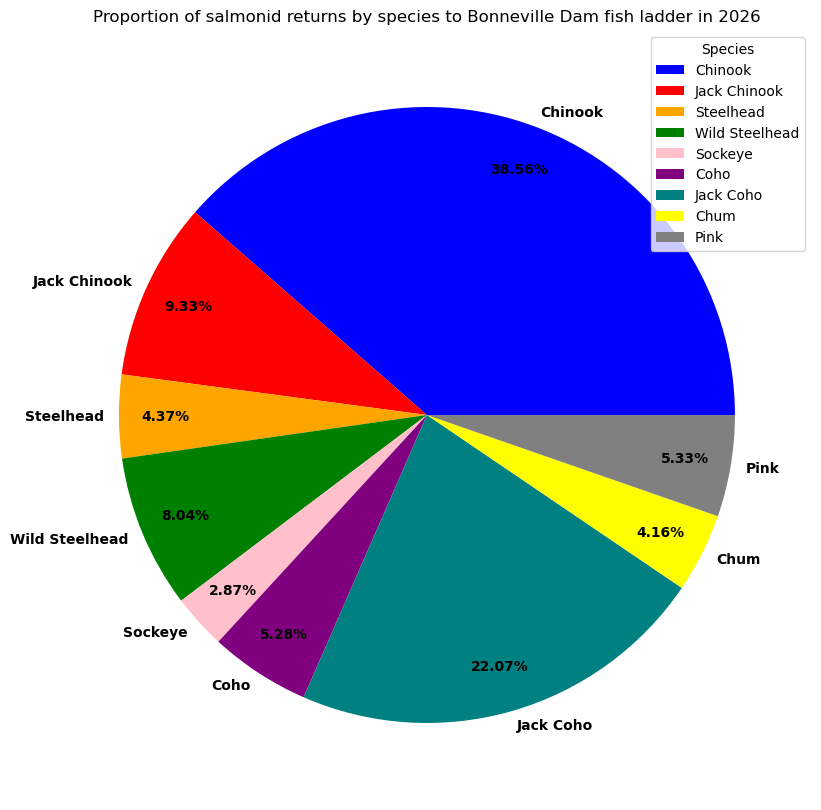

In [139]:
#pie graph with the proportion of different species returning to the bonneville dam

plt.figure(figsize= (10, 10))
#adjusted the size of the visualization

plt.pie(
    x =bonn_2026_df['bonneville'], 
    labels = bonn_2026_df['Species'], 
    autopct = '%.2f%%', 
    labeldistance= 1.05, 
    pctdistance = 0.85, 
    textprops={"fontweight": "bold"},
    colors = ('blue', 'red', 'orange', 'green', 'pink', 'purple', 'teal', 'yellow', 'grey')
)
#IN lines 6-13 I created the pie chart, specified where I wanted my labels and percentages to go, and added colors for each species.

plt.title('Proportion of salmonid returns by species to Bonneville Dam fish ladder in 2026')
plt.legend(title='Species', loc = 'upper right')
#I added a title and a legend that showed which color cooresponds to each species.

plt.show() 

Report: Chinook Salmon make up the highest proportion of fish counted at the Bonneville Dam at 38.56. Jack Chinook are also a part of the total Chinook population. They are a different type of male fish, and use a different mating strategy at the spawning ground. If we add these two percentages together, this species makes up 47.89% of the fish counted.  This finding is similar to the proportion of Chinook Salmon at Willamette Falls. When considering Steelhead, wild and hatchery, it only accounts for 12.41% of the total fish counted at Bonneville.  This data indicates that Chinook Salmon may be the best species to focus on when comparing the Columbia River and the Willamette River salmon populations.

The next highest porportion of the fish count at Bonneville was the Coho salmon. If we combine the Jack and Coho into one population, they make up 27.35% of the fish counted at Bonneville. Although this is almost a third of the fish counted, there are zero Coho counted at Willamette Falls. In order to keep the species variable as consistant as possible, I would not consider evaluating Coho as it is not present at both locations.

#### Sub-Section: 1.c.iv The Dalles Dam count 2026

In [140]:
#I am creating a new data frame to look at the fish counts at the Dalles Dam. 
#This locaton is on the Columbia river upstream from the Bonneville Dam.
#As fish migrate to spawning grounds, they swim upstream. First passing Bonneville and then passing the Dalles
dall_2026_df= chinook_to_other_species_df[['Species','dalles']]
dall_2026_df

,Species,dalles
0,Chinook,231946
1,Jack Chinook,61150
2,Steelhead,38601
3,Wild Steelhead,74575
4,Sockeye,25564
5,Coho,68222
6,Jack Coho,271512
7,Chum,27529
8,Pink,40213


In [141]:
sorted_dalles26= dall_2026_df.sort_values(by='dalles', ascending= False)
sorted_dalles26

,Species,dalles
6,Jack Coho,271512
0,Chinook,231946
3,Wild Steelhead,74575
5,Coho,68222
1,Jack Chinook,61150
8,Pink,40213
2,Steelhead,38601
7,Chum,27529
4,Sockeye,25564


In [142]:
#This csv will be used to create a dashboard in Tableau
sorted_dalles26.to_csv('species_to_dalles_26.csv', index=False)

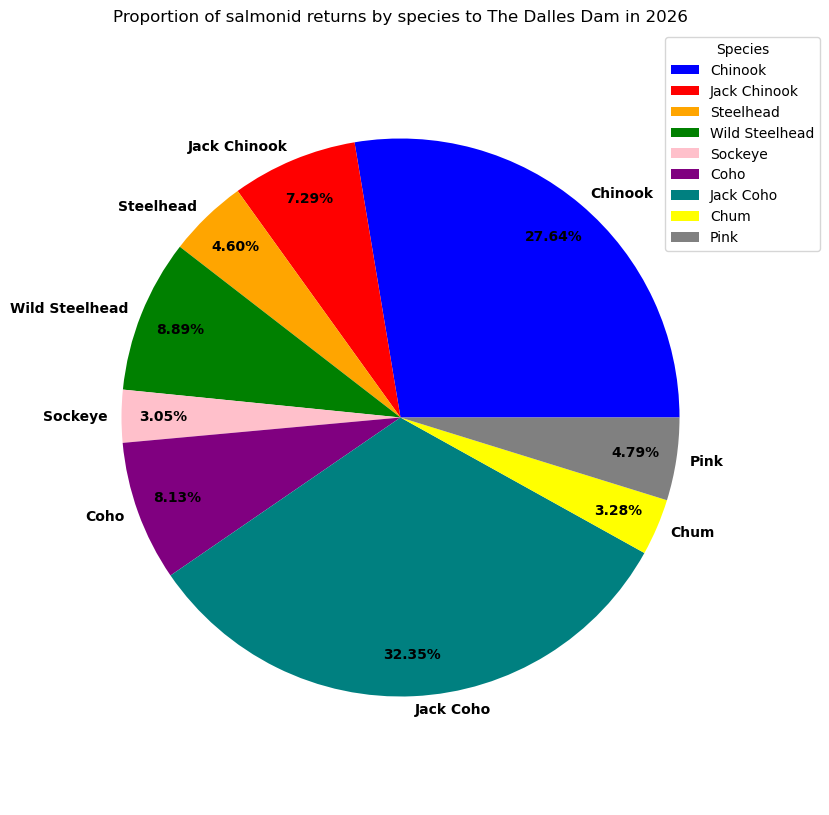

In [143]:
plt.figure(figsize= (10, 12))
#I set the overall size of the visualization

plt.pie(
    x =dall_2026_df['dalles'], 
    labels = dall_2026_df['Species'], 
    autopct = '%.2f%%', 
    labeldistance= 1.05, 
    pctdistance = 0.85, 
    textprops={"fontweight": "bold"},
    colors = ('blue', 'red', 'orange', 'green', 'pink', 'purple', 'teal', 'yellow', 'grey'),
    radius = 0.9
)
#lines 3-10 creates the pie chart. Here I did some adjustments to where the pie labels and percentage values are located.
#I made the chart radius slightly smaller to fit the legend without overlap

plt.title('Proportion of salmonid returns by species to The Dalles Dam in 2026')
plt.legend(title='Species', loc = 'upper right', bbox_to_anchor=(1.05, 1)
          )
#initially my legend overlapped with my chart labels, I had to give it a specific location so as
#not to overlap the labels.

plt.show() 

Report: At the Dalles Dam, Chinook (both jacks and normal type) make up 34.93% of the fish counted. When compared to Bonneville, which has 47.89% of the fish counts as Chinook, the Dalles has a smaller percentage of total Chinook. This finding is unexpected as the same fish are traveling upstream, and theoretically would pass both locations. If this was true, the percentages should be the same. Since they are not the same, further questions can be asked about what caused the difference? Possible explanations include recreational fishing, predation, poor water quality, or bias in the counting methods at each location. When I examined the fish counting procedures at both locations, I found that the fish counting process is unique to each location. Another finding that jumped out at me was that 40.48% of the fish counted were Coho at the Dalles. Bonneville counts revealed that only 27.35% were Coho. This could indicate a signficant loss of other species between locations, or a an undercount of Coho at Bonneville Dam, or an overcount at the Dalles due to inconsitant counting methods.

These proportions support findings from the previous comparison of Bonneville to Willamette Falls. Chinook salmon will the the species I focus on for the rest of the analysis.

Part 2: An examination of weighted means for fish counts at three locations (2016-2026)

Section 2.a Exploring the data

In [144]:
salmon_10yr_av= pd.read_excel('chinook_return_10yr_c.xlsx')

In [145]:
#there are no null values, and 1 string data type, and 3 number types.
salmon_10yr_av.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Species           9 non-null      object
 1   willamette_falls  9 non-null      int64 
 2   bonneville        9 non-null      int64 
 3   the_dalles        9 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 420.0+ bytes


In [146]:
#This is not helpful because the values in this df are already weighted means.
#In addition it considers the averages for all species, which does not help my analysis.
salmon_10yr_av.describe()

,willamette_falls,bonneville,the_dalles
count,9.000000,9.000000,9.000000
mean,6384.000000,129205.555556,91130.666667
std,10406.731439,171053.258279,119730.289326
min,0.000000,7164.000000,8022.000000
25%,0.000000,40179.000000,25564.000000
50%,1690.000000,61226.000000,38601.000000
75%,4959.000000,74033.000000,68222.000000
max,29940.000000,518188.000000,325595.000000


In [147]:
salmon_10yr_av.shape

(9, 4)

#### Section 2.b Comparison of species returning 10 year average species proportions at each location.

Subsection 2.b.i Willamette Falls

In [148]:
#calling just the fish count from willamette falls and sort from largest return to smallest return
willamette10_df= salmon_10yr_av[['Species','willamette_falls']]
will_10=willamette10_df.sort_values(by='willamette_falls', ascending= False)
will_10

,Species,willamette_falls
0,Chinook 10YearAvg,29940
2,Steelhead 10YearAvg,17416
7,Chum 10YearAvg,4959
6,Jack Coho 10YearAvg,1921
1,Jack Chinook 10YearAvg,1690
8,Pink 10YearAvg,1530
3,Wild Steelhead 10YearAvg,0
4,Sockeye 10YearAvg,0
5,Coho 10YearAvg,0


In [149]:
#saving as a csv to transfer to tableau
will_10.to_csv('willamette10.csv', index= False)

2.b.ii Bonneville Dam 10 year average salmon species counts

In [150]:
#pulling out just the bonneville species, and then sorting them from high ot low
bonn10_df= salmon_10yr_av[['Species','bonneville']]

In [151]:
# sorting the counts from highest to lowest
bonn_10s= bonn10_df.sort_values(by= 'bonneville', ascending= False)
bonn_10s

,Species,bonneville
0,Chinook 10YearAvg,518188
6,Jack Coho 10YearAvg,309403
5,Coho 10YearAvg,74033
1,Jack Chinook 10YearAvg,72890
2,Steelhead 10YearAvg,61226
7,Chum 10YearAvg,58348
4,Sockeye 10YearAvg,40179
3,Wild Steelhead 10YearAvg,21419
8,Pink 10YearAvg,7164


In [152]:
#dowloading csv for tableau
bonn_10s.to_csv('bonnaville10.csv', index= False)

2.b.iii The Dalles Dam 10 year average salmon species counts

In [153]:
#pulling out just the dalles location, and sorting the counts from high to low
dalles10_df= salmon_10yr_av[['Species','the_dalles']]
dall_10s = dalles10_df.sort_values(by='the_dalles', ascending= False)
dall_10s

,Species,the_dalles
0,Chinook 10YearAvg,325595
6,Jack Coho 10YearAvg,271512
5,Coho 10YearAvg,68222
1,Jack Chinook 10YearAvg,44229
2,Steelhead 10YearAvg,38601
7,Chum 10YearAvg,27529
4,Sockeye 10YearAvg,25564
3,Wild Steelhead 10YearAvg,10902
8,Pink 10YearAvg,8022


In [154]:
#converting to csv to put into tableau
dall_10s.to_csv('dalles10.csv', index= False)

2.b.iv  Bar graphs from each Location

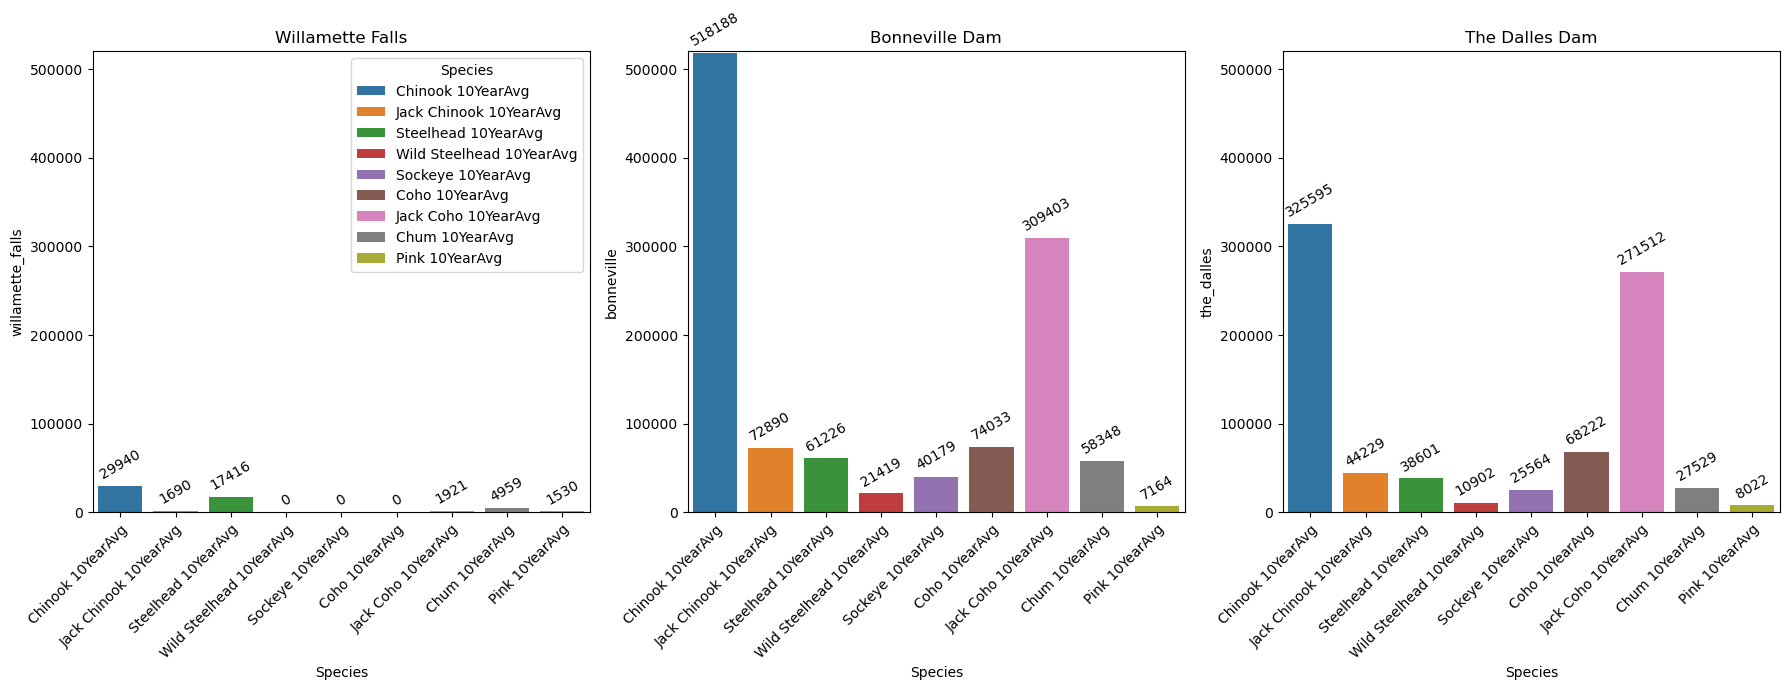

In [155]:
#This figure allows me to compare the 10 year av returns at all three locations 
#the y axis scale is the same on all three, so viewers can visually compare the returns.
fig, axes= plt.subplots(1, 3, figsize=(18,7))
#Line 3 shows that I am making three subplots within the full visualization, I also
#specified how larege the full visualization will be

sns.barplot( 
    data=willamette10_df,
    x= 'Species',
    y= 'willamette_falls', 
    hue='Species',
    palette="tab10",
    legend=True,
    ax= axes[0])
#The first bar plot shows fish returns at Willamette Falls. I used Seaborn
#The hues give each fish type a color, the legend can also be seen, and the x axis is labeled.
#it is specified in the subplot as axis[0] which is the first index position of the plots

sns.barplot( 
    data=bonn10_df,
    x= 'Species',
    y= 'bonneville', 
    hue='Species',
    palette="tab10",
    legend=False,
    ax= axes[1])
#This bar plot shows the fish returns at the Bonneville Dam.
#It is specified in the subplot as axis [1] which is the second index position of the plots.
#The same colors are used for the same species.

sns.barplot( 
    data= dalles10_df,
    x= 'Species',
    y= 'the_dalles',
    hue='Species',
    palette="tab10",
    legend=False,
    ax= axes[2])

#This bar pot shows the fish returns at the Bonneville Dam.
#It specifies in the subplot as axis[1] which is the second index position of the plots.
#It utilizes the same colors for each fish species as the previous 2 bar plots.

axes[0].set_title('Willamette Falls')
axes[1].set_title('Bonneville Dam')
axes[2].set_title('The Dalles Dam')
#Here I specify the titles for the three subplots


for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')
    ax.set_ylim(0, 520000)
    
#I created a for loop to collect the names of each species to label the x axis
#I also made sure the y axis had the same scale on all three graphs. 
# the alignment of the labels weren't matching up, so I used .get_ticklabels with ha= 'right' which
#specifies where the alignment should be lined up with the proper bar.
#520,000 was the highest level of returns to incorporate the overall max, which was 51,8188
#for the Bonneville Dam, so it is the upper bound of the y axis lim.

for ax in axes: 
    for container in ax.containers:
        ax.bar_label(
            container, fmt='%.0f', 
            padding = 3,
            rotation = 30
)
#This for loop allowed me to add values over each bar in each subplot

plt.tight_layout()
plt.show()

Report: The average count of all species at Willamette Falls (Willamette River) is much lower than at the other two locations. A few things could be reflected in this analysis. First, the Willamette River basin salmon populations are much smaller than the total populations in the Columbia river Basin because the area of accessible waterways is a lot smaller. The environment naturally supports lower numbers. Another factor that might be influencing these low averages is that these fish have to swim through heavily polluted waters near and inside the Portland Metro Area. There may be a lower survivorship by the time they reach the first Dam in the Willamette basin system.

Bonneville Dam and the Dalles Dam are both on the Columiba River. It is curious to see the reductions in average for all of the species. The Dalles if 45 miles upstream from the Bonneville Dam. This difference is worth analyzing further to determine factors that may cause the differences.
    

### 2.d. Further analysis of the three locations and differences in 10 year average counts.

2.d.i Finding the range of each location's data set.

In [156]:
#I am creating a for loop to collect the ranges of the 10 year average counts for the three locations.
#it takes the max value subtract the min value of each data set, and creates a range. 
#I can then compare the ranges to better understand the differences between the three locations.

for c in [
    willamette10_df['willamette_falls'], 
    bonn10_df['bonneville'], 
    dalles10_df['the_dalles']
]:
    print(c.max() - c.min())
    

29940
511024
317573


In [157]:
#creating a df for the range between the species with the highest average count to the species with the lowest average . 
#First I create a new column called location, and a new column called range 
#on the next line I put in values for both columns. I used the data from the loop above to give me the input numbers for the range variable
#the new data frame is called range_df
range_df= pd.DataFrame(columns= ['location', 'range'])

#now I am filling in rows for each column
range_df['location']= ['Willamette Falls', 'Bonneville Dam', 'The Dalles Dam']
range_df['range'] = [29940, 511024, 317573]

#looking at the new df
range_df

,location,range
0,Willamette Falls,29940
1,Bonneville Dam,511024
2,The Dalles Dam,317573


Report: Both the Bonneville Dam and the Dalles dam have a greater range of 10 year avg. counts. 
The range shows the difference between the species with the highest average count, and the species with the lowest average count.
It can tell us about the variability of the average count per species at each location. Since there are 9 different species, this give me
an idea about the biodiversity at each site, and which river supports more different species. Since Bonneville has the highest, there is greater biodiversity here than the other locations.  The pie graphs above tell me about the percentages of each species at each location.

In [158]:
#checking the data types of each variable
#Both have the appropriate data types
range_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   location  3 non-null      object
 1   range     3 non-null      int64 
dtypes: int64(1), object(1)
memory usage: 180.0+ bytes


In [159]:
#creating a csv to export to Tableau
range_df.to_csv('location_ranges.csv', index= False)

1.d.iii Comparison of sums of average fish counts between The Bonneville Dam and Willamette Falls Dam

In [160]:
#Taking the 10 year average data from each location, I will compare the sum of fish counted for each location
# First I created a new variable to compare the sum of all average fish counted at willamette falls to the sum of average counts at Bonneville. To get the percentage 
#I divided it by the sum of all species at Bonneville. Then I multiplied by 100. This will give me the total average counts compare between the two locations.

percentage_sum_wtob= willamette10_df['willamette_falls'].sum()/bonn10_df['bonneville'].sum()*100
print(f'{percentage_sum_wtob: .2f}%')

 4.94%


Report: There are a lot less fish total returning the Willamette Falls in the Willamette River, than those fish returning to the Columbia River. The Bonneville Dam has the highest number of fish returns compared to the other two locations. The percentage of total average fish from Willamette Falls makes up only 4.94% of the total returns from Bonneville. This shows how much smaller the total counts are for Willamette and Bonneville. I know that the Willamette River Basin is smaller than the Columbia River Basin, but are there other factors influencing this difference?

1.d.iv Comparisons of sums of average fish counts between The Bonneville Dam and The Dalles Dam.

In [161]:
# the sum of fish returned from The Dalles 10 year average makes up only 70% of total returns to Bonneville.
#First I created a new variable to compare the sum of all average fish counted at the dalles to the sum at Bonneville, and then divided it by the sum of all species at
#Bonneville. Then I multiplied by 100. This will give me the total average counts compare between the two locations.
percentage_sum_dtob= (dalles10_df['the_dalles'].sum()/bonn10_df['bonneville'].sum())*100
print(f'{percentage_sum_dtob: .2f}%')

 70.53%


Report: The Dalles average fish count has the middle range of average counts of species. When comparing Bonenville to the Dalles, the total return sums at The Dalles shows 70% of total returns to Bonneville. This is important because the Dalles is upstream of Bonneville Dam, and if all fish survived, the counts at Bonneville and the Dalles would be the same. Bonneville fish follow the Columbia River that skirts the northern edge of Portland Metro, and then enters forest land and plateaus as they swim upstream. There could be predation, fishing, or normal fish death due to natural selection in the 45 miles between Bonneville and the Dalles. Also there are hatcheries in this stretch. Are some of the fish in the species counts from these hatcheries? If so, those fish would end their migration journey and return to the hatcheries.

### Part 3 Examining the number of fish lost between The Bonneville Dam and the Dalles Dam in 2026

3.a Creating a new data frame finding the number lost fish in 2026

In [162]:
#I want to dig deeper into the differences in fish counts between Bonneville and upstream Dalles location. I am going back to use my fish counts from 2026
chinook_to_other_species_df.head(9)

,Species,willamette_falls,bonneville,dalles,year
0,Chinook,38568,540689,231946,2026
1,Jack Chinook,1054,130843,61150,2026
2,Steelhead,17416,61226,38601,2026
3,Wild Steelhead,11166,112730,74575,2026
4,Sockeye,0,40179,25564,2026
5,Coho,0,74033,68222,2026
6,Jack Coho,1921,309403,271512,2026
7,Chum,4959,58348,27529,2026
8,Pink,1732,74687,40213,2026


In [163]:
#As noted above there when comparing the averages of all fish at each location over 10 years
#there is a 30% reduction in total fish counts between Bonneville Dam and the Dalles Dam. 
#below I created a data frame to show the exact number of each species that is lost bewteen the two locations in 2026.

lost_fish = bonn_2026_df['bonneville']-dall_2026_df['dalles']
lost_fish_df= lost_fish.to_frame(name ='fish_lost_upstream_of_bonneville')
lost_fish_df['Species']= bonn_2026_df['Species']
lost_fish_df

,fish_lost_upstream_of_bonneville,Species
0,308743,Chinook
1,69693,Jack Chinook
2,22625,Steelhead
3,38155,Wild Steelhead
4,14615,Sockeye
5,5811,Coho
6,37891,Jack Coho
7,30819,Chum
8,34474,Pink


Section 3.b Turning the difference in counts into percentages for analysis

In [164]:
#Then I used these counts to developed a percentage of fish lost between locations.
#I took the lost fish info from above, divided by the total 
lost_fish_df['Percentage']= (
    lost_fish_df['fish_lost_upstream_of_bonneville']
    / bonn_2026_df['bonneville'].sum()
    *100).round(2)   
lost_fish_df

,fish_lost_upstream_of_bonneville,Species,Percentage
0,308743,Chinook,22.02
1,69693,Jack Chinook,4.97
2,22625,Steelhead,1.61
3,38155,Wild Steelhead,2.72
4,14615,Sockeye,1.04
5,5811,Coho,0.41
6,37891,Jack Coho,2.70
7,30819,Chum,2.20
8,34474,Pink,2.46


Report: Looking at the number of fish lost, Chinook has the greatest difference between locations.  One reason for this is that Chinook had the greatest average count to begin with. But this large number, combined with the percent loss of 22.02. This is a significant number of returning salmon that is lost after the first signficant river barrier. In future analyses I would gather more data about fishing limits during migrations as well as predation rates in this part of the river. In the past the Bonneville Dam has had issues with Sea Lions eating large numbers of fish as they are pass the fish ladders and are corralled through the same outlet pipe.

In [165]:
lost_fish_df.to_csv('lost_fish_2026.csv')

## Part 4 The change in number of Chinook salmon returning to streams upstream of Bonneville Dam from 1938-2025

Section 4.a Exploratory data analysis of yearly_chinook_df

In [166]:
#This data table shows the count of chinook salmon between 1938 and 2025 taken
#at the bonneville dam. This is the sum of fish counted going through the fish ladders.

yearly_chinook_df= pd.read_csv('chinook_over_time.csv')

yearly_chinook_df.head()

,year,chinook_count
0,1938,272395
1,1939,286156
2,1940,391573
3,1941,461443
4,1942,401998


In [167]:
yearly_chinook_df.tail()

,year,chinook_count
84,2022,752638
85,2023,722270
86,2024,648902
87,2025,632461
88,2026,540689


In [168]:
#there are 89 rows and 2 columns. This means that there are chinook population counts for 89 years.
yearly_chinook_df.shape

(89, 2)

In [169]:
#there are no null values, both columns are integers.
yearly_chinook_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   year           89 non-null     int64
 1   chinook_count  89 non-null     int64
dtypes: int64(2)
memory usage: 1.5 KB


In [170]:
yearly_chinook_df.describe()

,year,chinook_count
count,89.000000,8.900000e+01
mean,1982.000000,4.369637e+05
std,25.836021,2.204173e+05
min,1938.000000,1.856650e+05
25%,1960.000000,2.964290e+05
50%,1982.000000,3.732050e+05
75%,2004.000000,4.895230e+05
max,2026.000000,1.337101e+06


Section 4.b Creating a data table with statistics for the yearly chinook count data, exporting to Tabluea.

In [171]:
#The aggregations for column 2(chinook_count) may be valuable.
#I wanted to remove the values after the decimal so I used astype(int)
#The average number of chinook returning to Bonneville Dam over 89 years is 436,963
#The minimum fish count happened in 1938
#The max fish terturning was 2006
#The median number of fish returning was 272,205
stats_yearly_chinook = yearly_chinook_df.describe()
stats_yearly_chinook= stats_yearly_chinook.drop(columns= ['year'])
stats_yearly_chinook

,chinook_count
count,8.900000e+01
mean,4.369637e+05
std,2.204173e+05
min,1.856650e+05
25%,2.964290e+05
50%,3.732050e+05
75%,4.895230e+05
max,1.337101e+06


In [172]:
stats_yearly_chinook.to_csv('statistical_summary_chinook_returns.csv')

Report: The average number of chinook returning to Bonneville Dam over 89 years is 436,963 <br>
The minimum fish count happened in 1938<br>
The max fish counted was in 2006<br>
The median number of fish returning was 272,205<br>
This data raises questions about how the method of fish counting has changed over time. In 1938 the dam built one of the first fish ladder systems for salmon. 
After swimming up the ladder, the fish were kept in a holding pool where a woman would count the fish one by one and then release each individually upstream.
Today, there is a glass viewing window along the fish ladder. Park Rangers from the Department of Defense at the Bonneville Dam are hired as fish counters and use a clicker and data table to count fish that pass by the window. They have 9-5 working hours, and have a 34 minute break during each shift.  They use a calculation using daily data to estimate the fish that pass when they are on break. Also, when the visitor center is closed, there is an automated system that scans fish with fish tags. Each tag has cooresponding data about the salmon, and these are tabulated and put through a model to create accurate estimates that are comparible to the counts done by humans.  To me, both historic and modern counting methods could be a source of error. 

In addition, in populations there is a normal fluxuation in the population over time that is not considered to be part of the overall trend. This is called population dynamics. In scientific population studies scientists use mostly logarithmic or exponetial models to analyze populations because there are foundational factors such as the density of food, the density of individuals, and predation that factor into these models.  The statistics above do not address either of these common models, and just report on the raw fish count data.

4.c Calculating the population standard deviation for Chinook over time

In [173]:
#I am turning the yearly returns into a list, in preperation for calculating the standard deviation of a population.
yearly_returns= yearly_chinook_df['chinook_count']
yearly_returns_list=yearly_returns.tolist()
yearly_returns_list

[272395,
 286156,
 391573,
 461443,
 401998,
 313120,
 240763,
 297488,
 446152,
 480276,
 420555,
 277697,
 357375,
 331788,
 420879,
 332479,
 320947,
 359853,
 300917,
 403286,
 416419,
 345028,
 256049,
 281980,
 286625,
 278560,
 344422,
 317956,
 340111,
 366153,
 341128,
 507588,
 384780,
 405702,
 394456,
 398635,
 366759,
 425566,
 507773,
 366657,
 394600,
 276306,
 207770,
 232299,
 247911,
 185665,
 216465,
 296429,
 370729,
 468610,
 411896,
 373205,
 296525,
 226411,
 219688,
 259337,
 208197,
 189419,
 272884,
 360673,
 248860,
 306981,
 401711,
 867728,
 870035,
 921314,
 846026,
 570413,
 493708,
 275954,
 518942,
 480284,
 809799,
 677171,
 589937,
 1129664,
 1152642,
 1337101,
 697979,
 488981,
 336030,
 381773,
 535745,
 489523,
 752638,
 722270,
 648902,
 632461,
 540689]

3.ci Finding the standard deviation of the fish count

In [174]:
#I am using sptdev with the above list to do the population standard deviation. 
data= yearly_returns_list

pop_std= round(statistics.pstdev(data), 2)

print(f'Population std: {pop_std: .2f}')

Population std:  219175.54


Statistical Analysis: This standard deviation calcuation for populations looks at the variation in the yearly returns of chinook salmon population counts. It shows how much yearly population counts compared to the mean. The mean fish return is 436,963.70. This population std calcuation is different than the sample standard deviation because there is a complete count for every year of a full population of Chinook salmon. The .pstdev divides the sum of squared deviations by N instead of N-1. Since the population std, 219,175.4 is about half the number of the mean, which means there is a large amount of variation oin fish returns between 1938 and 2026.  I am not able to tell if this variation around the mean is related to normal population dynamics where populations fluxuate over time in normal cycles, or if this shows long-term changes over time.

The large amount of variation may be because salmon are very sensitive to their enviornments. Humans have caused many environmental changes that cause increasing pressures on the species. These presures include: overfishing, warming temperatures,reduced dissolved oxygen in the river, the presence of harmful chemicals, loss of spawning habitat, dams, and fishing. In fact these environmental factors have a cumulative effect on the population numbers when they return to the Columbia River. Scientists are still working on determining the influence of each factor on the species' populations.


Section 3.d Analyzing a histogram for chinook counts using plt.hist()

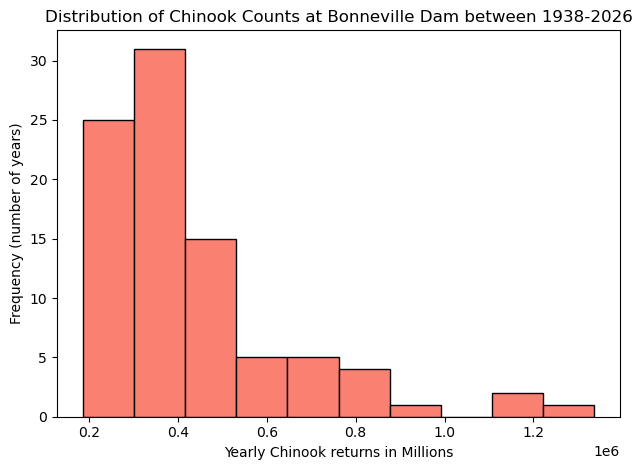

In [175]:
#This is a histogram showing the distribution of yearly returns.
#it starts with a high frequencies of years that return 200,000-400,000 fish.
#as the total number of fish increases the frequency of these numbers decrease--right skewed
plt.hist(
    yearly_chinook_df['chinook_count'],
    bins=10,
    edgecolor= 'black',
    color = 'salmon')

#the code below makes the tick marks line up better on the x axis
#I created a title for the visualization, an x axis title, and a y axis title
plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')
plt.title('Distribution of Chinook Counts at Bonneville Dam between 1938-2026')
plt.xlabel('Yearly Chinook returns in Millions')
plt.ylabel('Frequency (number of years)')
plt.tight_layout()
plt.show()

Report: In this analysis I am assuming that fish count represents the population of Chinook Salmon.
Each bin along the x axis is 200,000 fish. There were many years 20 and 30 eyars that had lower counts of between 200,000 nad 400,000 fish. The graph is skewed to the right meaning that there were very few years with high fish counts. There is a wide spread between 200,000 and 1.4 million. This shows large variation in the population which maybe influenced by negative environmental factors. A normal animal distribution would be a bell shape. The next step in this analysis would be making histograms for shorter time spans within the larger data set, to compare the distributions between earlier time periods and later time periods. I would also like to look closer at the data leading up to 1999 and the years just after 1999. In 99' Chinook were officially listed as "threatened" on the Endagered Species List, and people had to make changes like stop fishing, restore habitat, and bolster production in fish hatcheries.

Section 4.e Line graph with trend line

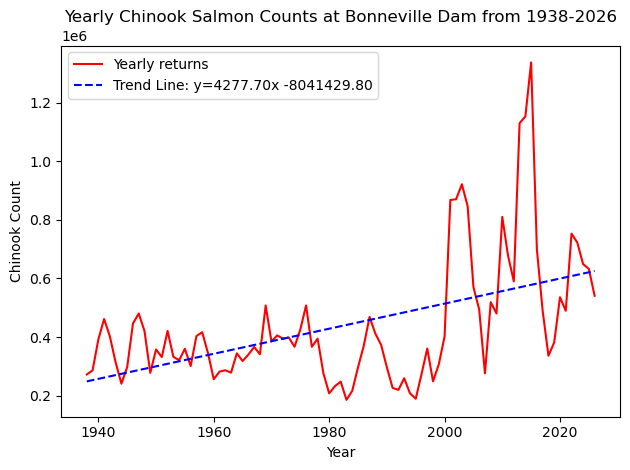

In [176]:
#Here is a line graph tracing the population over time with a trendline
#I also added a trenbd line using polyfit. First I defined the x and y variables, so I could then find the slope and intercept of these variables. 
#I also added a label that would show the equation for y=mx+b formula of a linier trend.
x=yearly_chinook_df['year']
y=yearly_chinook_df['chinook_count']

slope, intercept = np.polyfit(x,y,1)


plt.plot(
    x,
    y,
    color= 'red',
    label='Yearly returns'
)

plt.plot(
    x,
    slope*x+intercept,
    color= 'blue',
    linestyle= '--',
    label=f'Trend Line: y={slope:.2f}x {intercept:+.2f}'
)


plt.title('Yearly Chinook Salmon Counts at Bonneville Dam from 1938-2026')
plt.xlabel('Year')
plt.ylabel('Chinook Count')
plt.tight_layout()
plt.legend()
plt.show()

Overall chinook populations are increasing over time. Around 1999 you can see a steep decline, and then a general resurgence of the population after they were named 'Threatened' on the Endangered Species List. The noise-of cyclical increases and decreases of a population is common for a population and represents normal population dynamics. The linier trendline more clearly identfies a general pattern of increase. After being put on the list, fishing in the ocean and in the river were restricted, and many hatchery programs began to bring the population back.  The population is currently considered threatened and some restrictions have been lifted, although populations are closely managed.

In population biology, models are often exponetial or logrithmic. I will show a exponential trend line. The log model is used when examining a population's carrying capacity--the point where competition for food is so high that the population plateaus. Since Chinook salmon populations are overall low and 'threatened', I am going to assume the population is no where near the carrying capacity.

/var/folders/2z/m8yswkn57c75ydfhrrlddd900000gn/T/ipykernel_76130/2561629162.py:12: RuntimeWarning: overflow encountered in exp
  return a + np.exp(b* time)


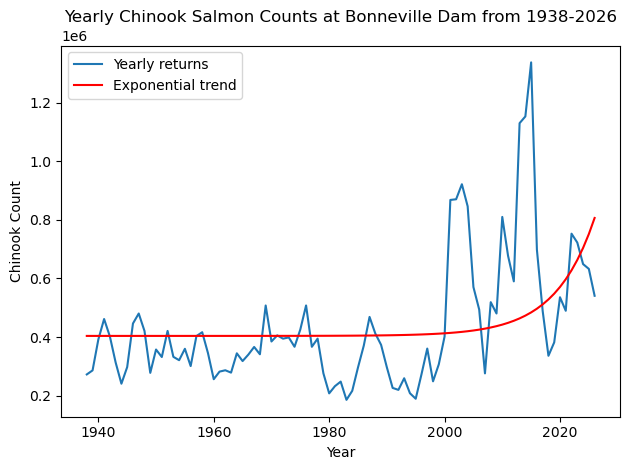

In [177]:
# I am defining my variables for the exponential model, and converts them to a numpy array
data = yearly_chinook_df[['year', 'chinook_count']].sort_values('year')
years = data['year'].to_numpy(dtype = float)
counts= data['chinook_count'].to_numpy(dtype= float)

# this gives me the total number of years of the data
time = years - years.min()

#creating the exponential curve starting at time 0
#b represents the positive or negative slope
def exponential(time, a, b):
    return a + np.exp(b* time)

# these parameters will find the best fit for my exponential curve
parameters, _ = scipy.optimize.curve_fit(
    exponential, 
    time,
    counts,
    p0= (counts.mean(), 0),
    maxfev= 10000   
)

#This plots the the fitted curve to the data line
plt.plot(years, counts, label= 'Yearly returns')
plt.plot(
    years,
    exponential(time, *parameters),
    color= 'red',
    label = 'Exponential trend'
)

#These are the labels for the plot
plt.title('Yearly Chinook Salmon Counts at Bonneville Dam from 1938-2026')
plt.xlabel('Year')
plt.ylabel('Chinook Count')
plt.tight_layout()
plt.legend()
plt.show()

In [178]:
#estimated annual percent change
a, b = parameters
annual_percent_change = (np.exp(b) - 1) * 100
print(f'Estimated annual change: {annual_percent_change:.2f}%')

Estimated annual change: 15.79%


Report. The exponential curve fits the data set better than the linier model. I calcuated that the percent change in fish counts is  an increase of 15.79%
This supports the trend that the population is growing, especially after 1999 benchmark of 'threatened' designation. It may point toward human efforts to support the population 
are effective.

Part 5: Looking at yearly returns at Willamette Falls between 1971-2024

In [179]:
historic_chinook_willf_df= pd.read_excel('willamette_falls_historic_totals.xlsx')

Section 5.a Exploratory Analysis of Chinook totals returning to Willamette Falls

In [180]:
historic_chinook_willf_df.head()

,year,spring_chinook,fall_chinook,total_yearly_chinook
0,1971,44569,5090,49659
1,1972,26154,11826,37980
2,1973,41960,22237,64197
3,1974,44530,34189,78719
4,1975,19079,33772,52851


In [181]:
#the data set have counts between 1971-2024
historic_chinook_willf_df.tail()

,year,spring_chinook,fall_chinook,total_yearly_chinook
49,2020,35012,3082,38094
50,2021,30025,3682,33707
51,2022,38629,3021,41650
52,2023,24089,1512,25601
53,2024,22592,1884,24476


In [182]:
#there are 54 rows and 4 columns in this dataset
historic_chinook_willf_df.shape

(54, 4)

In [183]:
#I can see if there are any null values, and what data type each of the columns are.
#year is technically a date, but it is fine that it is an int for this analysis
historic_chinook_willf_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   year                  54 non-null     int64
 1   spring_chinook        54 non-null     int64
 2   fall_chinook          54 non-null     int64
 3   total_yearly_chinook  54 non-null     int64
dtypes: int64(4)
memory usage: 1.8 KB


In [184]:
#I specifically just want to look at the total_yearly_chinook statistics.
#I want to round to see only one decimal place
#Here the mean is 48,238m and the max return year had 97514 fish
historic_chinook_willf_df.describe().round()

,year,spring_chinook,fall_chinook,total_yearly_chinook
count,54.0,54.0,54.0,54.0
mean,1998.0,39951.0,8288.0,48238.0
std,16.0,17919.0,9592.0,19302.0
min,1971.0,14672.0,352.0,18320.0
25%,1984.0,26907.0,1868.0,33716.0
50%,1998.0,36630.0,3555.0,41426.0
75%,2011.0,45002.0,11455.0,64093.0
max,2024.0,96725.0,34189.0,97514.0


5.b Histogram of frequency of chinook at Willamette Falls

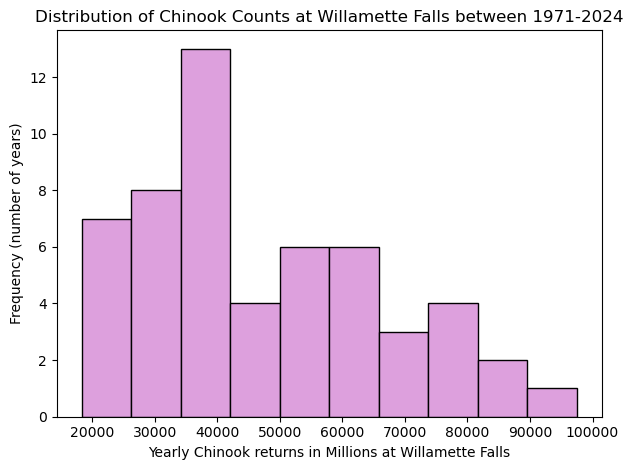

In [185]:
plt.hist(
    historic_chinook_willf_df['total_yearly_chinook'],
    bins=10,
    edgecolor= 'black',
    color = 'plum')

plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')
plt.title('Distribution of Chinook Counts at Willamette Falls between 1971-2024')
plt.xlabel('Yearly Chinook returns in Millions at Willamette Falls')
plt.ylabel('Frequency (number of years)')
plt.tight_layout()
plt.show()

Report: Willamette Falls has the highest frequency between 30,000-40,000 fish. This means the highest number of years had fish in between these two incriments. It shows a slight right skew meaning that most years there were lower numbers of returns, but looks more similar to a bell curve. There are overall less years in this data set so the frequencies are lower. 40,000 fish has the highest frequency of occuring in 13 different years. This data set's highest frequency is similar to the number of fish with the highest freqency at Bonneville Dam.  This may suggest that 300,000-400,000 fish returning is a consistant number for Chinook migrations.

3.d.iii Line graph of returns over time between 1971-2024 at Willamette Falls

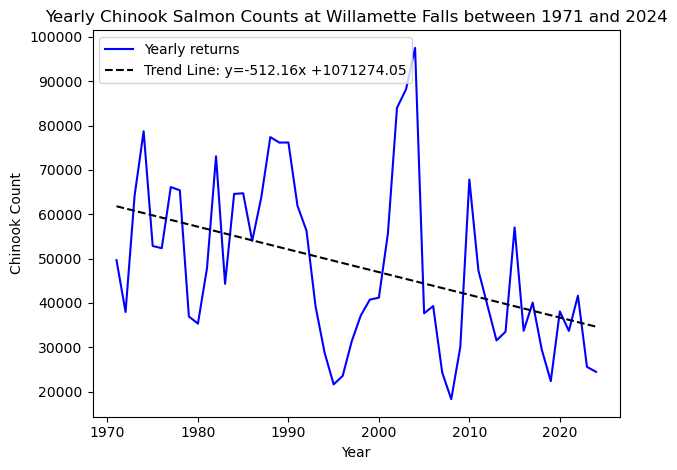

In [186]:
# I used the same format as the line graph for Bonneville Dam but used historic_chinook_willf_df

x=historic_chinook_willf_df['year']
y=historic_chinook_willf_df['total_yearly_chinook']


#this will give me values for the linier trend line
slope, intercept = np.polyfit(x,y,1)

#This builds the ilne graph
plt.plot(
    x,
    y,
    color= 'blue',
    label='Yearly returns'
)
#this adds the trend line
plt.plot(
    x,
    slope*x+intercept,
    color= 'black',
    linestyle= '--',
    label=f'Trend Line: y={slope:.2f}x {intercept:+.2f}'
)

#Here are all the labels
plt.title('Yearly Chinook Salmon Counts at Willamette Falls between 1971 and 2024')
plt.xlabel('Year')
plt.ylabel('Chinook Count')
plt.tight_layout()
plt.legend()
plt.show()

Report: Chinook Numbers at Willamette Falls have a negative trend. There is wide fluctuation of increases and decreases in the number of fish returning
due to population dynamics, but the pattern shows that the Chinook Population on the Willamette River is decreasing. One factor that may be at play is that Willamette River passes through more urban and industrial areas with higher levels of water pollution, than the Columbia River population. The next step in this analysis would be to set up an exponential model to see if it was a better fit for the data.

In [187]:
historic_chinook_willf_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   year                  54 non-null     int64
 1   spring_chinook        54 non-null     int64
 2   fall_chinook          54 non-null     int64
 3   total_yearly_chinook  54 non-null     int64
dtypes: int64(4)
memory usage: 1.8 KB


In [188]:
#When I analyze this data in Tableau, I just want column 1 and 3.
filt_will_yearly_returns = historic_chinook_willf_df.drop(columns=['spring_chinook', 'fall_chinook'])
filt_will_yearly_returns.head()

,year,total_yearly_chinook
0,1971,49659
1,1972,37980
2,1973,64197
3,1974,78719
4,1975,52851


In [189]:
filt_will_yearly_returns.to_csv('willamette_yearly_returns.csv')

Section 5.d Statistical Analyses of Yearly Returns at Willamette Falls and Bonneville Dam from 1971-20243.e

In [190]:
#bonneville Dam
yearly_chinook_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   year           89 non-null     int64
 1   chinook_count  89 non-null     int64
dtypes: int64(2)
memory usage: 1.5 KB


In [191]:
#willamette Falls
historic_chinook_willf_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   year                  54 non-null     int64
 1   spring_chinook        54 non-null     int64
 2   fall_chinook          54 non-null     int64
 3   total_yearly_chinook  54 non-null     int64
dtypes: int64(4)
memory usage: 1.8 KB


In [192]:
#renaming my df so it is more concise.
#cot= count over time
willamette_cot=filt_will_yearly_returns
bonneville_cot= yearly_chinook_df

In [193]:
#To do statistical analysis and compare the fish counts at both sites, I need to make sure that they cover the same timeframe
#Currently, the bonneville count goes from 1938-2026
print(bonneville_cot.max())
print(bonneville_cot.min())

year                2026
chinook_count    1337101
dtype: int64
year               1938
chinook_count    185665
dtype: int64


In [194]:
#the historical counts at Willamette Falls is between 1971-2024
print(willamette_cot.max())
print(willamette_cot.min())

year                     2024
total_yearly_chinook    97514
dtype: int64
year                     1971
total_yearly_chinook    18320
dtype: int64


In [195]:
year_range_filter=bonneville_cot['year'].isin(range(1971, 2025))

In [196]:
#new df ranging from 1971-2024
bonn_filtered_years_df= bonneville_cot[year_range_filter]

In [197]:
#confirming that my min value of filter is correct-year
bonn_filtered_years_df.min()

year               1971
chinook_count    185665
dtype: int64

In [198]:
#confirming that my max value of filter is correct-year
bonn_filtered_years_df.max()

year                2024
chinook_count    1337101
dtype: int64

In [199]:
# Null Hypothesis: There is no linear corrolation between the yearly Chinook fish counts at these two locations.
#Alternative Hypothesis: There is a linear corrolation between the yearly Chinook fish counts at these two locations.

r, p_value= scipy.stats.pearsonr(
    bonn_filtered_years_df['chinook_count'],
    willamette_cot['total_yearly_chinook']
)
print(f'r= {r:.4f}')
print(f'p value = {p_value: .4f}')

r= 0.1242
p value =  0.3708


Report: The r value (corrolation coefficient) suggests a very small positive relationship between fish counts between 1971-2024,but the p value is greater than 0.05 showing that the r value is not statisically significant. We fail to reject the null hypothesis because there.

This makes sense when considering salmon sub-populations. When the fish are in the ocean, they may be mixed, but when they return to spawn they always return to the stream where they were born. Chinook Salmon returning to the Willamette river basin split from those returning to the Columbia Basin at the confluence of both rivers north of Portland, Oregon. The Columbia river basin fish will be counted at the Bonneville Dam, and the Upper Willamette river fish will be counted at Willamette Falls.  

The other factor that impacts this comparison. The Columbia river basin covered 7582 water miles of Chinook habitat, and the willamette river basin only covers 1240 stream miles of Chinook habitat. This means I can not directly compare the two fish counts over time directly. It makes sense that there are less total Chinook in the Willamette sub-population because the area is smaller.  To account for this difference I am going to use a 

Direct comparison of fish population using a baseline index.

In [200]:
#Columbia river miles of streams upstream of Bonneville Dam for Chinook salmon
columbia_river_cmiles = 7582

In [201]:
#Willamette river miles of stream upstream of Willamette Falls for Chinook Salmon
willamette_river_cmiles = 1240

In [202]:
print(willamette_cot)
print(bonn_filtered_years_df)

    year  total_yearly_chinook
0   1971                 49659
1   1972                 37980
2   1973                 64197
3   1974                 78719
4   1975                 52851
5   1976                 52354
6   1977                 66136
7   1978                 65414
8   1979                 36964
9   1980                 35358
10  1981                 47832
11  1982                 73078
12  1983                 44322
13  1984                 64596
14  1985                 64736
15  1986                 54002
16  1987                 63781
17  1988                 77406
18  1989                 76165
19  1990                 76185
20  1991                 61953
21  1992                 56295
22  1993                 39250
23  1994                 28794
24  1995                 21649
25  1996                 23569
26  1997                 31377
27  1998                 37183
28  1999                 40762
29  2000                 41202
30  2001                 55723
31  2002

Section 5.e Making a baseline index comparison-
By looking at the baseline index of each population, I can find their relative differences between the Columbia river and the Willamette River.

In [203]:
#To create a baseline filters-count over time
baseline_year_w = willamette_cot['year'].between(1971,1975)
baseline_year_c = bonn_filtered_years_df['year'].between(1971,1975)

Subsection 5.3.i Willamette Falls index

In [204]:
#baseline means which will be the reference level for each population.
#this line finds the mean of just the first 5 rows. 
baseline_w_mean= willamette_cot.loc[baseline_year_w, 'total_yearly_chinook'].mean()

#This is creating a column that has the ratio how each year compares to the population baseline average and multiply by 100.
#this will tell me what each year's count is compared to its baseline.
willamette_cot['baseline_index'] = (willamette_cot['total_yearly_chinook'])/ baseline_w_mean * 100
willamette_cot.head()
will_baseline_df = willamette_cot

#This is the data frame with the baseline index for the Willamette River returns
will_baseline_df.head()

,year,total_yearly_chinook,baseline_index
0,1971,49659,87.611060
1,1972,37980,67.006344
2,1973,64197,113.259776
3,1974,78719,138.880264
4,1975,52851,93.242557


In [205]:
#Once the extra column was dropped, I then renamed the original index column to include which river it was from.
will_baseline_df.rename({'baseline_index': 'baseline_index_will'}, axis = 1)
will_baseline_df.head()

,year,total_yearly_chinook,baseline_index
0,1971,49659,87.611060
1,1972,37980,67.006344
2,1973,64197,113.259776
3,1974,78719,138.880264
4,1975,52851,93.242557


In [206]:
will_baseline_df.to_csv('willamette_baseline_index.csv')

Subsection 5.e.ii Columbia's baseline index

In [207]:
#From now on I want to use the filtered list for bonneville's fish counts that span the same years as willamette.
#This should be 1971-2024
#looking at the .describe method, I can see the min is 1971 and max is 2024, which confirms 
#that the time variable in both data sets are the same.
#fbonn = filtered bonneville years
fbonn_cot=bonn_filtered_years_df
fbonn_cot.describe()

,year,chinook_count
count,54.000000,5.400000e+01
mean,1997.500000,4.839385e+05
std,15.732133,2.648493e+05
min,1971.000000,1.856650e+05
25%,1984.250000,2.813368e+05
50%,1997.500000,4.001730e+05
75%,2010.750000,5.850560e+05
max,2024.000000,1.337101e+06


In [208]:
#Here I am using the fbonn_cot because it only includes the same years 
#as at Willamette Falls. The years must be the same for each location.
#I find the average of the first 5 years, which creates the baseline value
baseline_c_mean = fbonn_cot.loc[baseline_year_c, 'chinook_count'].mean()

#Now I am creating the ratio of each year's value to the baseline average above, and then it is converted into a percent
#of the baseline average.
fbonn_cot['baseline_index'] = (fbonn_cot['chinook_count']/ baseline_c_mean * 100)
bonn_baseline_df = fbonn_cot
bonn_baseline_df.head()

/var/folders/2z/m8yswkn57c75ydfhrrlddd900000gn/T/ipykernel_76130/1214589226.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fbonn_cot['baseline_index'] = (fbonn_cot['chinook_count']/ baseline_c_mean * 100)


,year,chinook_count,baseline_index
33,1971,405702,101.877940
34,1972,394456,99.053898
35,1973,398635,100.103309
36,1974,366759,92.098761
37,1975,425566,106.866092


Report: These percentages can give us a reference to how the population changed in the Columbia River using the baseline index.
For example, compared to the baseline reference, 1971's fish count at Willamette falls was 101% compared to the baseline. This mean year 1's counts 
were about the same as the 5 year average.  Now that I have these percentages I can compare the two

In [209]:
#I need to do the same renaming of the baseline index column, so it is distinct from the willamette index.
bonn_baseline_df = bonn_baseline_df.rename({'baseline_index': 'baseline_index_col'}, axis = 1)
bonn_baseline_df.head()

,year,chinook_count,baseline_index_col
33,1971,405702,101.877940
34,1972,394456,99.053898
35,1973,398635,100.103309
36,1974,366759,92.098761
37,1975,425566,106.866092


In [210]:
#sending this data to Tableau
bonn_baseline_df.to_csv('Columbia_baseline_index.csv')

### Part 6: Water Quality Data using the Oregon Water Quality Index along the Willamette River, between 2016-2024

4.a. Data exploration

In [211]:
#I am importing the spreadsheet with the data
wat_qual_df = pd.read_excel('full_water_quality_data.xlsx')

In [212]:
#I am looking at the columns for the first 5 rows to make sure they match the columns in the excel sheet.
wat_qual_df.head()

,Water Year,Station ID,Station Description,Basin Name,Land Use,Sample Date,Temp. (°C),DO (mg/L),DO (%),BOD (mg/L),...,OWQI Score,Temp..1,DO.1,BOD.1,pH.1,Total Solids.1,N.1,P.1,Bact..1,OWQI Status
0,2016,10332,Willamette River at SP&S RR Bridge (Portland),Willamette - Lower,Urban,2016-06-23,18.6,10.8,115,1.6,...,85.475625,Good,Fair,Poor,Excellent,Fair,Good,Good,Excellent,Good
1,2016,10332,Willamette River at SP&S RR Bridge (Portland),Willamette - Lower,Urban,2016-04-28,14.4,10.8,105,0.7,...,90.390198,Excellent,Excellent,Good,Excellent,Good,Poor,Good,Excellent,Excellent
2,2016,10332,Willamette River at SP&S RR Bridge (Portland),Willamette - Lower,Urban,2016-02-18,9.5,11.9,106,4.6,...,72.720593,Excellent,Excellent,Very Poor,Excellent,Good,Poor,Good,Excellent,Poor
3,2016,10332,Willamette River at SP&S RR Bridge (Portland),Willamette - Lower,Urban,2015-10-01,18.2,9.8,103,1.1,...,87.612617,Good,Excellent,Fair,Excellent,Fair,Good,Fair,Excellent,Good
4,2016,10332,Willamette River at SP&S RR Bridge (Portland),Willamette - Lower,Urban,2015-12-29,6.4,13.7,110,2.6,...,79.636804,Excellent,Good,Poor,Excellent,Good,Poor,Poor,Excellent,Fair


In [213]:
#I am looking at all of the different stations descriptions in the original excel file.
#I only want the sampling locations that coorespond to the fish count data that I have.
wat_qual_df['Station Description'].value_counts()

Station Description
North Santiam River at Greens Bridge                    61
Willamette River at Marion Street (Salem)               60
Willamette River at Albany (eastbound Hwy 20 bridge)    60
Calapooia River at Hwy 99E                              59
Clackamas River at High Rocks (Old Hwy 213)             59
                                                        ..
South Fork Coos River at Anson Rogers Bridge            37
Whitehorse Creek at Whitehorse Ranch Road               34
Crooked Creek at Kiger Road                             34
South Fork Blitzen River at Blitzen Crossing            25
Skipanon River at Hwy 101                               24
Name: count, Length: 160, dtype: int64

In [214]:
#I want to see all of the data types, and I want to make sure they are correct.
#it looks like the date was convered to Python default, and rows 23-31 are all strings because they are words that match the OWQI 
#values that are calucated by the state of Oregon by using a statistical model to rate the average water quality by year.
wat_qual_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8055 entries, 0 to 8054
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Water Year                         8055 non-null   int64         
 1   Station ID                         8055 non-null   int64         
 2   Station Description                8055 non-null   object        
 3   Basin Name                         8055 non-null   object        
 4   Land Use                           8055 non-null   object        
 5   Sample Date                        8055 non-null   datetime64[ns]
 6   Temp. (°C)                         8055 non-null   float64       
 7   DO (mg/L)                          8055 non-null   float64       
 8   DO (%)                             8055 non-null   int64         
 9   BOD (mg/L)                         8055 non-null   float64       
 10  pH (SU)                            8

In [215]:
wat_qual_df.shape

(8055, 34)

Sub-section 6.a.i  removing na values

In [216]:
# looking for the columns with na values.
wat_qual_df.isna().sum()

Water Year                           0
Station ID                           0
Station Description                  0
Basin Name                           0
Land Use                             0
Sample Date                          0
Temp. (°C)                           0
DO (mg/L)                            0
DO (%)                               0
BOD (mg/L)                           0
pH (SU)                              0
Total Solids (mg/L)                  0
Ammonia as N (mg/L)                  0
Nitrate as N (mg/L)                  0
Phosphorus            as P (mg/L)    0
Bact. (E. coli) (MPN)                1
Temp.                                0
DO                                   0
BOD                                  0
pH                                   0
Total Solids                         0
N                                    0
P                                    0
Bact.                                2
OWQI Score                           1
Temp..1                  

In [217]:
# another way to look at na values for columns.
wat_qual_df.count()

Water Year                           8055
Station ID                           8055
Station Description                  8055
Basin Name                           8055
Land Use                             8055
Sample Date                          8055
Temp. (°C)                           8055
DO (mg/L)                            8055
DO (%)                               8055
BOD (mg/L)                           8055
pH (SU)                              8055
Total Solids (mg/L)                  8055
Ammonia as N (mg/L)                  8055
Nitrate as N (mg/L)                  8055
Phosphorus            as P (mg/L)    8055
Bact. (E. coli) (MPN)                8054
Temp.                                8055
DO                                   8055
BOD                                  8055
pH                                   8055
Total Solids                         8055
N                                    8055
P                                    8055
Bact.                             

In [218]:
#The numeric column with a single na value is Bact. (E.coli) (MRN). 
#I will not be focusing on this measure directly, so I'm ok with deleting the row using
#dropna.  I specify the column using the parameter subset.
#'Bact. Score' and 'OWQI Status' are strings, so I am fine leaving these values blank

wat_qual_df= wat_qual_df.dropna(subset= ['Bact. (E. coli) (MPN)'])

In [219]:
# I am double checking with rows have NaN in Bact. Status. These are listed in locations I am going to filter out anyway, so I will not try to drop them.
pd.set_option('display.max_columns', None)
wat_qual_df[wat_qual_df.isna().any(axis=1)]

,Water Year,Station ID,Station Description,Basin Name,Land Use,Sample Date,Temp. (°C),DO (mg/L),DO (%),BOD (mg/L),pH (SU),Total Solids (mg/L),Ammonia as N (mg/L),Nitrate as N (mg/L),Phosphorus as P (mg/L),Bact. (E. coli) (MPN),Temp.,DO,BOD,pH,Total Solids,N,P,Bact.,OWQI Score,Temp..1,DO.1,BOD.1,pH.1,Total Solids.1,N.1,P.1,Bact..1,OWQI Status
147,2024,10344,Willamette River at Wheatland Ferry,Willamette - Middle,Agriculture,2024-06-12,19.0,10.2,109,0.7,7.7,59,0.049,0.223,0.04,2.0,58.273207,81.07624,85.262112,100.0,76.008221,99.655221,91.014875,NaN,90.106532,Fair,Excellent,Good,Excellent,Excellent,Good,Good,Excellent,Excellent
1391,2025,10442,South Umpqua at Melrose Road,Umpqua,Mixed,2025-01-13,7.4,12.2,100,1.3,7.8,82,0.005,0.273,0.04,19.0,58.273207,81.07624,85.262112,100.0,76.008221,99.655221,91.014875,NaN,89.887797,Excellent,Excellent,Poor,Excellent,Poor,Good,Good,Excellent,Excellent


In [220]:
#I am rechecking na values, and they are gone from the numeric data.
#the two NA values remaining are for categorical variables, and will not change data set
#by keeping them.
wat_qual_df.isna().sum()

Water Year                           0
Station ID                           0
Station Description                  0
Basin Name                           0
Land Use                             0
Sample Date                          0
Temp. (°C)                           0
DO (mg/L)                            0
DO (%)                               0
BOD (mg/L)                           0
pH (SU)                              0
Total Solids (mg/L)                  0
Ammonia as N (mg/L)                  0
Nitrate as N (mg/L)                  0
Phosphorus            as P (mg/L)    0
Bact. (E. coli) (MPN)                0
Temp.                                0
DO                                   0
BOD                                  0
pH                                   0
Total Solids                         0
N                                    0
P                                    0
Bact.                                2
OWQI Score                           0
Temp..1                  

Section 6.b  Filtering quantitative data by sampling location

Sub-Section 6.b.i  Creating a Location filter

In [221]:
# I am creating a filter for 4 stations out of this data set.
#The full data set contains all locations in Oregon.
#I am just choosing teh locations that coorespond to the locations I have for all species counts, 
#and historic chinook counts.

station_filter= wat_qual_df['Station Description'].isin([
        'Willamette River at Hawthorne Bridge', 
        'Columbia River at Marker #47 (upstream of Willamette River)', 
        'Swan Island Channel Midpoint',
        'Columbia Slough at Landfill Road',
])
        
filtered_stations_df= wat_qual_df[station_filter]
filtered_stations_df.head()
    

,Water Year,Station ID,Station Description,Basin Name,Land Use,Sample Date,Temp. (°C),DO (mg/L),DO (%),BOD (mg/L),pH (SU),Total Solids (mg/L),Ammonia as N (mg/L),Nitrate as N (mg/L),Phosphorus as P (mg/L),Bact. (E. coli) (MPN),Temp.,DO,BOD,pH,Total Solids,N,P,Bact.,OWQI Score,Temp..1,DO.1,BOD.1,pH.1,Total Solids.1,N.1,P.1,Bact..1,OWQI Status
2420,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2015-12-29,6.4,13.6,108,2.2,7.6,69,0.045,0.937,0.08,55.0,93.832706,82.120710,86.978433,85.586725,81.178713,98.201991,88.019779,98.000000,80.695790,Excellent,Excellent,Poor,Excellent,Good,Poor,Poor,Excellent,Fair
2421,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-04-28,13.0,11.1,105,1.0,7.9,66,0.049,0.428,0.05,7.0,100.000000,98.810136,58.385069,100.000000,90.153436,99.183660,79.034322,94.526718,89.720983,Excellent,Excellent,Fair,Excellent,Good,Fair,Good,Excellent,Excellent
2422,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-06-23,18.5,9.9,105,0.5,7.9,74,0.054,0.311,0.05,5.0,100.000000,100.000000,78.728891,77.151436,91.514100,99.188228,82.029502,95.443242,89.493029,Good,Excellent,Excellent,Excellent,Fair,Good,Good,Excellent,Good
2423,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-08-10,21.4,8.9,99,0.8,7.6,78,0.080,0.348,0.06,3.0,100.000000,100.000000,78.728891,100.000000,90.153436,97.840880,82.029502,93.369631,85.201263,Poor,Excellent,Good,Excellent,Fair,Fair,Fair,Excellent,Good
2424,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-02-18,9.5,11.9,106,1.4,7.3,74,0.053,0.707,0.06,50.0,100.000000,100.000000,90.515417,90.144162,94.297347,98.089001,82.029502,94.656734,85.547946,Excellent,Excellent,Poor,Excellent,Fair,Poor,Fair,Excellent,Good


4.b.ii Checking the filter and exporting to a csv

In [222]:
filtered_stations_df['Station Description'].value_counts()

Station Description
Willamette River at Hawthorne Bridge                           52
Swan Island Channel Midpoint                                   52
Columbia River at Marker #47 (upstream of Willamette River)    51
Columbia Slough at Landfill Road                               49
Name: count, dtype: int64

In [223]:
filtered_stations_df

,Water Year,Station ID,Station Description,Basin Name,Land Use,Sample Date,Temp. (°C),DO (mg/L),DO (%),BOD (mg/L),pH (SU),Total Solids (mg/L),Ammonia as N (mg/L),Nitrate as N (mg/L),Phosphorus as P (mg/L),Bact. (E. coli) (MPN),Temp.,DO,BOD,pH,Total Solids,N,P,Bact.,OWQI Score,Temp..1,DO.1,BOD.1,pH.1,Total Solids.1,N.1,P.1,Bact..1,OWQI Status
2420,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2015-12-29,6.4,13.6,108,2.2,7.6,69,0.045,0.937,0.08,55.0,93.832706,82.120710,86.978433,85.586725,81.178713,98.201991,88.019779,98.000000,80.695790,Excellent,Excellent,Poor,Excellent,Good,Poor,Poor,Excellent,Fair
2421,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-04-28,13.0,11.1,105,1.0,7.9,66,0.049,0.428,0.05,7.0,100.000000,98.810136,58.385069,100.000000,90.153436,99.183660,79.034322,94.526718,89.720983,Excellent,Excellent,Fair,Excellent,Good,Fair,Good,Excellent,Excellent
2422,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-06-23,18.5,9.9,105,0.5,7.9,74,0.054,0.311,0.05,5.0,100.000000,100.000000,78.728891,77.151436,91.514100,99.188228,82.029502,95.443242,89.493029,Good,Excellent,Excellent,Excellent,Fair,Good,Good,Excellent,Good
2423,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-08-10,21.4,8.9,99,0.8,7.6,78,0.080,0.348,0.06,3.0,100.000000,100.000000,78.728891,100.000000,90.153436,97.840880,82.029502,93.369631,85.201263,Poor,Excellent,Good,Excellent,Fair,Fair,Fair,Excellent,Good
2424,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-02-18,9.5,11.9,106,1.4,7.3,74,0.053,0.707,0.06,50.0,100.000000,100.000000,90.515417,90.144162,94.297347,98.089001,82.029502,94.656734,85.547946,Excellent,Excellent,Poor,Excellent,Fair,Poor,Fair,Excellent,Good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4539,2024,11201,Columbia Slough at Landfill Road,Willamette - Lower,Urban,2024-02-22,9.8,11.9,103,3.1,7.5,171,0.005,1.840,0.14,53.0,100.000000,98.781990,85.262112,100.000000,75.008925,67.547036,76.039114,95.443242,63.136421,Excellent,Excellent,Very Poor,Excellent,Very Poor,Very Poor,Very Poor,Excellent,Poor
4540,2024,11201,Columbia Slough at Landfill Road,Willamette - Lower,Urban,2024-04-23,16.0,13.6,138,5.0,7.7,210,0.014,1.350,0.21,14.0,82.262114,76.618160,78.728891,100.000000,45.113932,43.452361,73.043879,69.884556,51.759682,Excellent,Poor,Very Poor,Excellent,Very Poor,Very Poor,Very Poor,Excellent,Very Poor
4541,2024,11201,Columbia Slough at Landfill Road,Willamette - Lower,Urban,2024-06-20,21.6,12.1,137,3.1,8.1,198,0.011,1.160,0.13,219.0,87.426121,85.086000,92.337486,100.000000,55.758569,10.000000,79.034322,92.359859,60.747636,Poor,Poor,Very Poor,Excellent,Very Poor,Very Poor,Poor,Poor,Poor
4542,2025,11201,Columbia Slough at Landfill Road,Willamette - Lower,Urban,2024-12-19,8.2,9.1,77,1.6,7.2,147,0.118,1.470,0.13,57.0,88.138098,98.810136,92.337486,100.000000,74.218624,84.217580,85.024654,61.980122,70.150562,Excellent,Excellent,Poor,Excellent,Very Poor,Very Poor,Poor,Excellent,Poor


In [224]:
#this csv will have all of the columns for the four locations in my analysis
filtered_stations_df.to_csv('wq_at4_pdx.csv')

 6.b.iii Creating Yearly Averages for the measurements and index values per location
#### Hawthorne Bridge on the Willamette River water quality measurements and indicies

In [225]:
#in order to keep track of the locations of these collections, I first need to split up the table by individual location.
#that way the year and station descriptions don't get dropped when I aggregate because they are categorical/strings.
#This is a filter for sample site: Hawthorne Bridge
loc_hawthorne_w_df= filtered_stations_df.loc[filtered_stations_df['Station Description'] =='Willamette River at Hawthorne Bridge'].copy()
loc_hawthorne_w_df.head()

,Water Year,Station ID,Station Description,Basin Name,Land Use,Sample Date,Temp. (°C),DO (mg/L),DO (%),BOD (mg/L),pH (SU),Total Solids (mg/L),Ammonia as N (mg/L),Nitrate as N (mg/L),Phosphorus as P (mg/L),Bact. (E. coli) (MPN),Temp.,DO,BOD,pH,Total Solids,N,P,Bact.,OWQI Score,Temp..1,DO.1,BOD.1,pH.1,Total Solids.1,N.1,P.1,Bact..1,OWQI Status
2420,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2015-12-29,6.4,13.6,108,2.2,7.6,69,0.045,0.937,0.08,55.0,93.832706,82.120710,86.978433,85.586725,81.178713,98.201991,88.019779,98.000000,80.695790,Excellent,Excellent,Poor,Excellent,Good,Poor,Poor,Excellent,Fair
2421,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-04-28,13.0,11.1,105,1.0,7.9,66,0.049,0.428,0.05,7.0,100.000000,98.810136,58.385069,100.000000,90.153436,99.183660,79.034322,94.526718,89.720983,Excellent,Excellent,Fair,Excellent,Good,Fair,Good,Excellent,Excellent
2422,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-06-23,18.5,9.9,105,0.5,7.9,74,0.054,0.311,0.05,5.0,100.000000,100.000000,78.728891,77.151436,91.514100,99.188228,82.029502,95.443242,89.493029,Good,Excellent,Excellent,Excellent,Fair,Good,Good,Excellent,Good
2423,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-08-10,21.4,8.9,99,0.8,7.6,78,0.080,0.348,0.06,3.0,100.000000,100.000000,78.728891,100.000000,90.153436,97.840880,82.029502,93.369631,85.201263,Poor,Excellent,Good,Excellent,Fair,Fair,Fair,Excellent,Good
2424,2016,10611,Willamette River at Hawthorne Bridge,Willamette - Lower,Urban,2016-02-18,9.5,11.9,106,1.4,7.3,74,0.053,0.707,0.06,50.0,100.000000,100.000000,90.515417,90.144162,94.297347,98.089001,82.029502,94.656734,85.547946,Excellent,Excellent,Poor,Excellent,Fair,Poor,Fair,Excellent,Good


In [226]:
#This data frame will have the year and the average yearly values for the raw water quality measurements at the Hawthorne Bridge
avg_wq_haw = loc_hawthorne_w_df.groupby('Water Year')[loc_hawthorne_w_df.columns[6:16]].mean()
.head()

SyntaxError: invalid syntax (3347973543.py, line 3)

In [ ]:
avg_wq_haw.to_csv('hawthorne_avg_wq_measurements.csv')

In [ ]:
#This data frame will have the year and the average yearly Oregon Water Quality Index scores at the Hawthorne Bridge
avg_index_haw = loc_hawthorne_w_df.groupby('Water Year')[loc_hawthorne_w_df.columns[16:25]].mean()
avg_index_haw.head()

In [ ]:
#exporting to I can use in Tableau
avg_index_haw.to_csv('hawthorne_avg_index.csv')

### Subsection 6.b.iv Swan Island Channel Midpoint water quality measurements and indicies

In [ ]:
#This is a filter to just select data from the Marker #47
loc_swan_w_df= filtered_stations_df.loc[filtered_stations_df['Station Description'] =='Swan Island Channel Midpoint'].copy()
loc_swan_w_df.head()

In [ ]:
#This data frame will have the year and the average yearly values for the raw water quality measurements at Swan Island
avg_wq_swan = loc_swan_w_df.groupby('Water Year')[loc_swan_w_df.columns[6:16]].mean()
avg_wq_swan.head()

In [ ]:
#exporting to I can use in Tableau
avg_wq_swan.to_csv('swan_island_avg_wq_measurements.csv')

In [ ]:
#This data frame will have the year and the average yearly Oregon Water Quality Index scores at Swan Island
avg_index_swan = loc_swan_w_df.groupby('Water Year')[loc_swan_w_df.columns[16:25]].mean()
avg_index_swan.head()

In [ ]:
#exporting data to Tableau
avg_index_swan.to_csv('swan_island_avg_index.csv')

Subsection 6.b.v Columbia River at Marker 47 (upstream of Willamette River) measurements and indicies

In [ ]:
#This is a filter to just select data from the Marker #47
loc_47_c_df= filtered_stations_df.loc[filtered_stations_df['Station Description'] =='Columbia River at Marker #47 (upstream of Willamette River)'].copy()
loc_47_c_df.head()

In [ ]:
#This will display years and average yearly water quality measurements from the Columbia river sample site: Marker 47
avg_wq_47 = loc_47_c_df.groupby('Water Year')[loc_47_c_df.columns[6:16]].mean()
avg_wq_47.head()

In [ ]:
#sending this data as a csv to Tableau
avg_wq_47.to_csv('marker_47_avg_wq_measurements.csv')

In [ ]:

avg_index_47 = loc_47_c_df.groupby('Water Year')[loc_47_c_df.columns[16:25]].mean()
avg_index_47.head()

In [ ]:
#sending this data as a csv to Tableau
avg_index_47.to_csv('47_avg_index.csv')

Sub-section 6.b.vi Columbia Slough at Landfill Road water quality measurements and indicies

In [ ]:
#I am creating a filter to just select data from the Columbia Slough location
loc_slough_c_df= filtered_stations_df.loc[filtered_stations_df['Station Description'] =='Columbia Slough at Landfill Road'].copy()
loc_47_c_df.head()

In [ ]:
#This will display years and average yearly water quality measurements from the Columbia river sample site: Slough
avg_wq_slough = loc_slough_c_df.groupby('Water Year')[loc_slough_c_df.columns[6:24]].mean()
avg_wq_slough.head()

In [ ]:
#sending this data as a csv to Tableau
avg_wq_slough.to_csv('columbia_slough_avg_wq_measurements.csv')

In [ ]:
#This will display years and average yearly water quality measurements from the Columbia river sample site: Slough
avg_index_slough = loc_slough_c_df.groupby('Water Year')[loc_slough_c_df.columns[16:25]].mean()
avg_index_slough.head()

In [ ]:
#sending this data as a csv to Tableau
avg_index_slough.to_csv('slough_avg_index.csv')

4.c Statistical Analysis for water Quality Measurement Data

In [ ]:
# using the previously created loc_47_c_df, which filters the columns just by specific sample locations,
#i can create a new df that shows the average water quality index score, 
avg_owqi_47 = loc_47_c_df.groupby('Water Year')[loc_47_c_df.columns[16:25]].mean()
avg_owqi_47

In [ ]:
avg_owqi_47.to_csv('columbia_47_avg_wq_index')

In [ ]:
avg_owqi_haw= loc_hawthorne_w_df.groupby('Water Year')[loc_47_c_df.columns[16:25]].mean()
avg_owqi_haw

In [ ]:
avg_owqi_haw.to_csv('willamette_hawthorne_avg_wq_index.csv')

Section 6.c Water Quality Index categories

In [ ]:
index_key_df =pd.DataFrame(columns= ['very_poor', 'poor', 'fair', 'good', 'excellent'])

In [ ]:
index_key_df['very_poor'] = ['0-60']
index_key_df['poor'] = ['61-79']
index_key_df['fair'] = ['80-84']
index_key_df['good'] = ['85-89']
index_key_df['excellent'] = ['90-100']

index_key_df

In [ ]:
#By creating a key for the OWQI statuses, I can create calculated fields and filters for the score data
#in Tabluea
index_key_df.to_csv('OWQI_cat_key.csv')

Report: analysis for this data will be in the Tableau dashboard.

#### Part 7 Creating a df with location data for mapping in Tableau

In [ ]:
location_df= pd.DataFrame(columns= ['location_name','river', 'latitude', 'longitude'])
location_df

In [ ]:
#the columbia slough location is an ambiant monitoring stations monitored by DEQ, 3 miles upstream of confluence of willamette and columbia
#columbia marker 47# is managed by DEQ 102 miles upstream from the ocean
#hawthorne bridge is monitored by USGS and Portland bureau of Environmental Services (BES)
#swan island midpoint is monitored by the DEQ (.5 miles upstream from confluence of columbia)
location_df['location_name']= [
    'Willamette River at Hawthorne Bridge',
    'Swan Island Channel Midpoint',
    'Columbia River at Marker #47 (upstream of Willamette River)',
    'Columbia Slough at Landfill Road',
    'Bonneville Dam',
    'The Dalles Dam',
    'Willamette Falls'
]

In [ ]:
#this column represents the river system each site is part of
location_df['river']=[
    'willamette',
    'willamette',
    'columbia',
    'willamette',
    'columbia',
    'columbia',
    'willamette'
]

In [ ]:
#these are the latitudes of the monitoring stations as decimals as well as sampling locatons
#I used the escape back slash to indicate that the single quotes and double quotes represent minutes and seconds in lat and long measures.
location_df['latitude']= [
    45.517500,
    45.565833,
    45.513310,
    45.608056, 
    45.637895,
    45.613611,
    45.351390
]

In [ ]:
#this represents the longitudes of these monitoring stations and fish sampling locations with minutes and seconds.
#I used escape backslash to indicate that the single quotes and dob
location_df['longitude']= [
    -122.671389,
    -122.716111,
    -122.669890,
    -122.745000,
    -121.947026,
    -121.133333,
    -122.619170
]

In [ ]:
location_df.head(8)

In [ ]:
#creating a csv to export to Tableau
location_df.to_csv('sample_and_monitoring_sites_loc.csv')

In [ ]:
#chekcing the data types. 
location_df.info()

Report: These data points will help to creat a graph that provides context for the locations and sample sites in this analaysis.